# UTS Graf Sains Data: Rekomendasi RetailRocket dengan Neo4j (AuraDB)

Nama: Putri Manika Rukmamaya | NIM: 23031554091 | Periode: P1 2015-06-12 s.d. sebelum 2015-07-03, P2 2015-07-24 s.d. sebelum 2015-08-14

Catatan: graf dijalankan di Neo4j AuraDB. Kredensial dibaca dari `.env` dan tidak diunggah. Versi driver `neo4j` 6.4.1; `requirements.txt` diubah ke `neo4j>=5.20` karena `execute_query` tidak tersedia di versi 4.x.

In [1]:
from dotenv import load_dotenv
print("ok")

ok


In [ ]:
load_dotenv(override=True)
URI  = os.getenv("NEO4J_URI")
AUTH = (os.getenv("NEO4J_USER"), os.getenv("NEO4J_PASSWORD"))
print(URI)   

neo4j+s://ef1fb47b.databases.neo4j.io


In [1]:
import pandas as pd

df_raw = pd.read_csv("data/events.csv")
df_raw["dt"] = pd.to_datetime(df_raw["timestamp"], unit="ms")   # epoch ms, UTC
print(df_raw.shape, df_raw.dt.min(), df_raw.dt.max())

P1 = ("2015-06-12", "2015-07-03")   # train: >= awal, < akhir
P2 = ("2015-07-24", "2015-08-14")   # test
tr = df_raw[(df_raw.dt >= P1[0]) & (df_raw.dt < P1[1])]
te = df_raw[(df_raw.dt >= P2[0]) & (df_raw.dt < P2[1])]
print("sebelum filter user:", len(tr), len(te))

cnt = tr.visitorid.value_counts()
tr = tr[tr.visitorid.isin(cnt[cnt >= 3].index)]
cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
tr[cols].to_csv("data/train_events.csv", index=False)
te[cols].to_csv("data/test_events.csv", index=False)
print("train:", len(tr), "| user:", tr.visitorid.nunique(), "| item:", tr.itemid.nunique(), "| test:", len(te))

**2.1: Periode waktu dan filter**

**No. 1-2**

Data `events.csv` berisi 2.756.101 interaksi pada 3 Mei - 18 Sep 2015. Kolom `timestamp` berupa epoch milidetik, dikonversi ke datetime (UTC).

- P1 (train): 2015-06-12 <= t < 2015-07-03 -> 416.564 baris
- P2 (test): 2015-07-24 <= t < 2015-08-14 -> 431.332 baris

Batas awal inklusif, batas akhir eksklusif. Pada data train, hanya visitor dengan minimal 3 event yang dipertahankan, untuk mengecilkan graf (batas AuraDB Free dan waktu proses) dan membuang user dengan informasi sangat sedikit. Hasil akhir train: 199.527 baris, 29.786 visitor, 43.605 item (view 187.020; addtocart 9.102; transaction 3.405). Data test tidak difilter dan hanya dipakai untuk evaluasi (1.607 visitor ada di train dan test). Hasil disimpan di `data/train_events.csv` dan `data/test_events.csv`.

In [ ]:
import os, time
import numpy as np, pandas as pd
from tqdm import tqdm
from dotenv import load_dotenv
from neo4j import GraphDatabase

load_dotenv()
URI  = os.getenv("NEO4J_URI")
AUTH = (os.getenv("NEO4J_USER"), os.getenv("NEO4J_PASSWORD"))
CSV  = "data/train_events.csv"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print(driver.execute_query("RETURN 1 AS x").records[0]["x"])

1


In [ ]:
with driver.session() as s:
    s.run("CREATE CONSTRAINT v_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    s.run("CREATE CONSTRAINT i_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

df = pd.read_csv(CSV)
df["transactionid"] = df["transactionid"].apply(lambda x: "" if pd.isna(x) else str(int(x)))
print(df.shape)

t = time.time()
sample = df.head(200)
with driver.session() as s:
    s.run("UNWIND $rows AS r MERGE (:Visitor {visitorId: r.visitorid})",
          rows=sample[["visitorid"]].to_dict("records")).consume()
print(round(time.time() - t, 2), "detik untuk 200 baris")

(199527, 5)
1.71 detik untuk 200 baris


In [ ]:
from neo4j import RoutingControl

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

**1.2 Checkpoint**

1. Database yang dipakai: `neo4j` (database default), terlihat pada `database_="neo4j"`.
2. Akses ke database lain dalam satu instance: `USE namadb` / `:use namadb` di Cypher, parameter `database_="namadb"` atau `driver.session(database="namadb")` di driver, dan perintah administrasi di database `system` (`SHOW DATABASES`, `CREATE DATABASE`).
3. Jenis graf: graf berarah (`KNOWS` dari Arthur ke temannya), tidak berbobot, berbentuk property graph dengan satu label simpul (`Person`) dan satu tipe relasi.

In [ ]:
driver.execute_query("MATCH (p:Person) DETACH DELETE p")

In [ ]:
def run_batches(query, rows, size=1000, desc=""):
    def work(tx, batch):
        tx.run(query, rows=batch).consume()
    with driver.session() as s:
        for i in tqdm(range(0, len(rows), size), desc=desc):
            s.execute_write(work, rows[i:i+size])

# tahap 1: simpul 
run_batches("UNWIND $rows AS r MERGE (:Visitor {visitorId: r})",
            [int(x) for x in df.visitorid.unique()], desc="Visitor")
run_batches("UNWIND $rows AS r MERGE (:Item {itemId: r})",
            [int(x) for x in df.itemid.unique()], desc="Item")

# tahap 2: relasi per jenis event
base = ("UNWIND $rows AS r "
        "MATCH (v:Visitor {visitorId: r.visitorid}) MATCH (i:Item {itemId: r.itemid}) ")
queries = {
    "view": base + "CREATE (v)-[:VIEWED {timestamp: r.timestamp}]->(i)",
    "addtocart": base + "CREATE (v)-[:ADDED_TO_CART {timestamp: r.timestamp}]->(i)",
    "transaction": base + "CREATE (v)-[:BOUGHT {timestamp: r.timestamp, transactionId: r.transactionid}]->(i)",
}
for ev, q in queries.items():
    rows = df[df.event == ev][["timestamp", "visitorid", "itemid", "transactionid"]].to_dict("records")
    run_batches(q, rows, desc=ev)

print("Import selesai.")

Visitor:   0%|          | 0/30 [00:00<?, ?it/s][#E574]  _: <CONNECTION> error: Failed to read from defunct connection ResolvedIPv4Address(('34.124.212.239', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Unable to retrieve routing information
Transaction failed and will be retried in 0.9229960865985377s (Unable to retrieve routing information)
[#E575]  _: <CONNECTION> error: Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Transaction failed and will be retried in 2.233339248518511s (Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))))
transaction: 100%|██████████| 4/4 [00:01<00:00,  2.63it/s]

Import selesai.


In [5]:
for q in ["MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah",
          "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"]:
    recs, _, _ = driver.execute_query(q)
    print(pd.DataFrame([r.data() for r in recs]), "\n")

[#D7E7]  _: <CONNECTION> error: Failed to read from defunct connection ResolvedIPv4Address(('34.124.212.239', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Unable to retrieve routing information
Transaction failed and will be retried in 1.1729386572217853s (Unable to retrieve routing information)
[#D7E4]  _: <CONNECTION> error: Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Transaction failed and will be retried in 1.7009085117433491s (Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))))


     jenis  jumlah
0  Visitor   29786
1     Item   43605 

          relasi  jumlah
0         VIEWED  187020
1  ADDED_TO_CART    9102
2         BOUGHT    3405 



**2.1: Komposisi subgraph**

**No. 3**

Hanya data train yang dimuat ke graf. Skema: `(:Visitor {visitorId})-[:VIEWED | :ADDED_TO_CART | :BOUGHT]->(:Item {itemId})`. Impor dimodifikasi dari template menjadi tiga tahap (simpul, lalu relasi per jenis event) agar lebih ringan; graf yang dihasilkan sama.

Cypher yang dipakai:
- `MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah`: `MATCH (n)` mengambil semua simpul, `labels(n)[0]` mengambil label tiap simpul, `count(*)` menghitung jumlah per label (agregasi dikelompokkan berdasarkan kolom lain di `RETURN`).
- `MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah`: mengambil semua relasi lalu menghitungnya per tipe.

Hasil: Visitor 29.786; Item 43.605; VIEWED 187.020; ADDED_TO_CART 9.102; BOUGHT 3.405 (total 199.527 relasi, sama dengan jumlah baris train).

In [6]:
import numpy as np, pandas as pd, scipy.sparse as sp

recs, _, _ = driver.execute_query("""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS visitorid, i.itemId AS itemid, type(r) AS t, count(*) AS n""")
g = pd.DataFrame([r.data() for r in recs])
g["w"] = g.t.map({"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}) * g.n
d = g.groupby(["visitorid", "itemid"], as_index=False).w.sum()

users = d.visitorid.astype("category")
items = d.itemid.astype("category")
X = sp.csr_matrix((d.w, (users.cat.codes, items.cat.codes)),
                  shape=(len(users.cat.categories), len(items.cat.categories)))
print("shape:", X.shape, "| nnz:", X.nnz, "| density:", X.nnz / (X.shape[0] * X.shape[1]))
print("rata2 item/user:", X.getnnz(axis=1).mean(), "| rata2 user/item:", X.getnnz(axis=0).mean())

[#D04C]  _: <CONNECTION> error: Failed to read from defunct connection ResolvedIPv4Address(('34.124.212.239', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Unable to retrieve routing information
Transaction failed and will be retried in 1.0850134447448818s (Unable to retrieve routing information)
[#D04F]  _: <CONNECTION> error: Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Transaction failed and will be retried in 2.1113383503186407s (Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))))


shape: (29786, 43605) | nnz: 118790 | density: 9.146004407559538e-05
rata2 item/user: 3.9881152219163365 | rata2 user/item: 2.724228872835684


VSM User : tiap user = vektor berdimensi 43605 (jumlah item)
VSM Item : tiap item = vektor berdimensi 29786 (jumlah user)
sparsity : 0.9999085399559244
item per user (min/median/max): 1 3.0 1072
user per item (min/median/max): 1 1.0 163


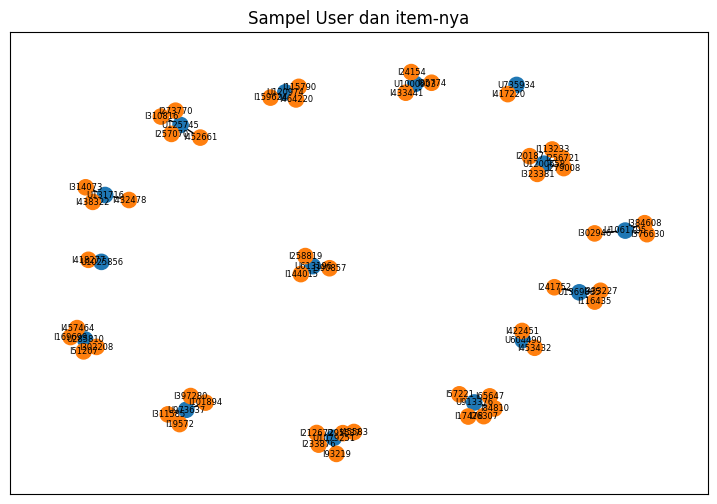

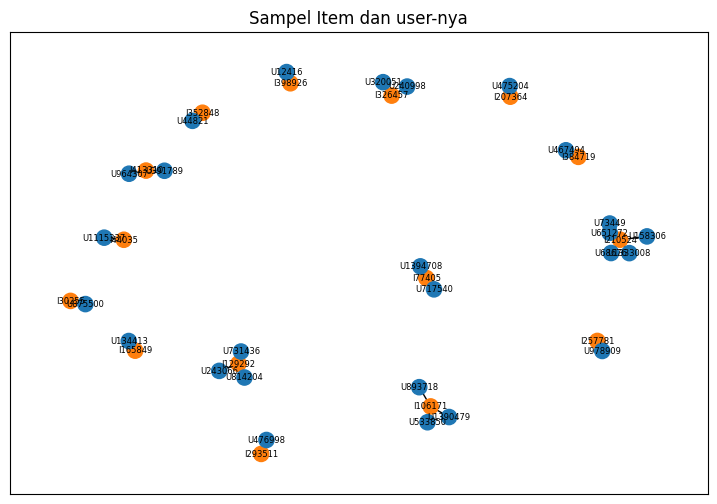

In [ ]:
import networkx as nx, matplotlib.pyplot as plt

rng = np.random.default_rng(42)

print("VSM User : tiap user = vektor berdimensi", X.shape[1], "(jumlah item)")
print("VSM Item : tiap item = vektor berdimensi", X.shape[0], "(jumlah user)")
print("sparsity :", 1 - X.nnz / (X.shape[0] * X.shape[1]))
print("item per user (min/median/max):", X.getnnz(axis=1).min(), np.median(X.getnnz(axis=1)), X.getnnz(axis=1).max())
print("user per item (min/median/max):", X.getnnz(axis=0).min(), np.median(X.getnnz(axis=0)), X.getnnz(axis=0).max())

# plot 1: sampel user + item tetangga
G1 = nx.Graph()
for u in rng.choice(X.shape[0], 15, replace=False):
    for j in X[u].indices[:5]:
        G1.add_edge(f"U{users.cat.categories[u]}", f"I{items.cat.categories[j]}")
plt.figure(figsize=(9, 6))
nx.draw_networkx(G1, node_color=["tab:blue" if n[0] == "U" else "tab:orange" for n in G1],
                 node_size=120, font_size=6)
plt.title("Sampel User dan item-nya"); plt.show()

# plot 2: sampel item + user tetangga
XT = X.T.tocsr()
G2 = nx.Graph()
for i in rng.choice(XT.shape[0], 15, replace=False):
    for u in XT[i].indices[:5]:
        G2.add_edge(f"I{items.cat.categories[i]}", f"U{users.cat.categories[u]}")
plt.figure(figsize=(9, 6))
nx.draw_networkx(G2, node_color=["tab:orange" if n[0] == "I" else "tab:blue" for n in G2],
                 node_size=120, font_size=6)
plt.title("Sampel Item dan user-nya"); plt.show()

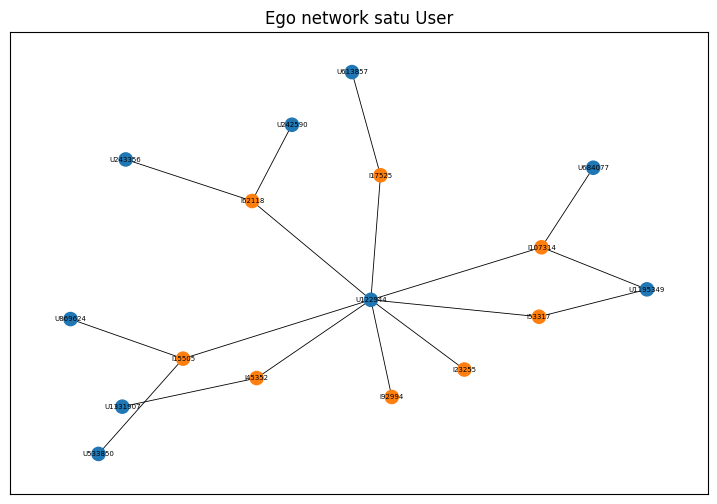

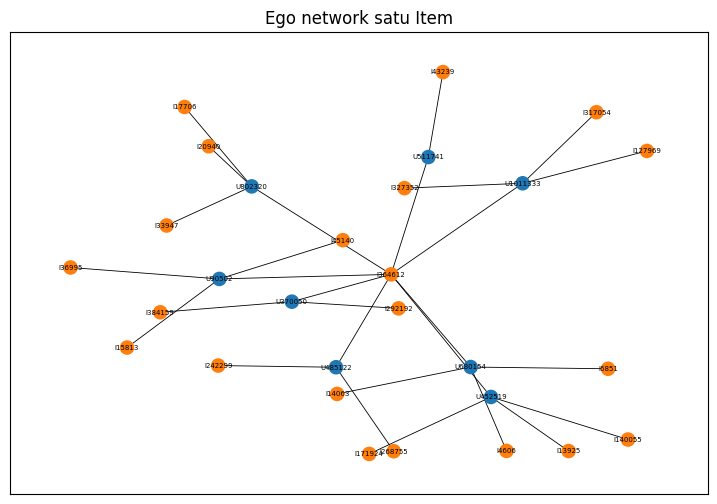

In [ ]:
rng = np.random.default_rng(42)
XT = X.T.tocsr()
U = lambda u: f"U{users.cat.categories[u]}"
I = lambda i: f"I{items.cat.categories[i]}"

def draw(G, title):
    plt.figure(figsize=(9, 6))
    pos = nx.spring_layout(G, seed=42, k=0.5)
    nx.draw_networkx(G, pos, node_color=["tab:blue" if n[0] == "U" else "tab:orange" for n in G],
                     node_size=90, font_size=5, width=0.6)
    plt.title(title); plt.show()

# ego user
u0 = int(rng.choice(np.where(X.getnnz(axis=1) >= 10)[0]))
G1 = nx.Graph()
for j in X[u0].indices[:8]:
    G1.add_edge(U(u0), I(j))
    for u in XT[j].indices[:3]:
        G1.add_edge(I(j), U(u))
draw(G1, "Ego network satu User")

# ego item
i0 = int(rng.choice(np.where(X.getnnz(axis=0) >= 10)[0]))
G2 = nx.Graph()
for u in XT[i0].indices[:8]:
    G2.add_edge(I(i0), U(u))
    for j in X[u].indices[:3]:
        G2.add_edge(U(u), I(j))
draw(G2, "Ego network satu Item")

**2.1: Vector Space Model User dan Item**

**No. 4-5**

Matriks X (baris = user, kolom = item), sel = jumlah bobot interaksi: view = 1, addtocart = 3, transaction = 5 (asumsi: sinyal minat makin kuat). Matriks dibangun dari graf lewat query Cypher.

- VSM User: tiap user adalah vektor berdimensi 43.605 (jumlah item). Median 3 item per user (min 1, maks 1.072).
- VSM Item: tiap item adalah vektor berdimensi 29.786 (jumlah user). Median 1 user per item (min 1, maks 163).
- Shape X = (29.786, 43.605); sparsity 99,99%.

Plot networkx: sampel acak memperlihatkan simpul-simpul yang hampir tidak saling terhubung (konsekuensi sparsity). Plot ego-network memperlihatkan kemiripan terbentuk lewat item atau user yang dibagi. Biru = user, oranye = item.

In [ ]:
import time

B = (X > 0).astype(np.float32).tocsr()
su = rng.choice(B.shape[0], 2000, replace=False)
si = rng.choice(B.shape[1], 2000, replace=False)

t = time.time(); UU = B[su] @ B.T;    t_uu = time.time() - t
t = time.time(); II = B.T[si] @ B;    t_ii = time.time() - t
print("user-user: density", UU.nnz / (2000 * B.shape[0]), "| waktu", round(t_uu, 2), "detik | ukuran penuh", B.shape[0], "x", B.shape[0])
print("item-item: density", II.nnz / (2000 * B.shape[1]), "| waktu", round(t_ii, 2), "detik | ukuran penuh", B.shape[1], "x", B.shape[1])

user-user: density 0.001026136439938226 | waktu 0.04 detik | ukuran penuh 29786 x 29786
item-item: density 0.002892604059167527 | waktu 0.05 detik | ukuran penuh 43605 x 43605


**2.1: Proyeksi yang lebih baik**

**No. 6**

Estimasi dari sampel 2.000 simpul:

| | user-user | item-item |
|---|---|---|
| Ukuran penuh | 29.786 x 29.786 | 43.605 x 43.605 |
| Density | 0,00103 | 0,00289 |
| Tetangga rata-rata per simpul | sekitar 31 | sekitar 126 |
| Perkiraan entri nonzero | sekitar 0,9 juta | sekitar 5,5 juta |
| Waktu sampel | 0,04 dtk | 0,05 dtk |

Proyeksi user-user dipilih: lebih kecil dan lebih sparse (sekitar 6x lebih sedikit entri), dan sesuai dengan KNN berbasis user di 2.2. Proyeksi item-item lebih padat karena user dengan banyak item membentuk klik besar. Angka di atas estimasi dari sampel, bukan proyeksi penuh.

In [10]:
from sklearn.preprocessing import normalize

Xn = normalize(X)
deg = X.getnnz(axis=1)
ref = int(np.random.default_rng(42).choice(np.where(deg >= 10)[0]))   # user acuan, minimal 10 item
ref_id = int(users.cat.categories[ref])
sims = (Xn @ Xn[ref].T).toarray().ravel(); sims[ref] = -1
top5 = np.argsort(-sims)[:5]
print("user acuan:", ref_id)
print(pd.DataFrame({"visitorId": users.cat.categories[top5], "cosine": sims[top5]}))

user acuan: 122944
   visitorId    cosine
0     271927  0.333333
1     242590  0.298142
2     243356  0.288675
3     684077  0.223607
4     746281  0.144338


**2.1: Similarity dan penulisan ke graf**

**No. 7-8**

User acuan: 122944 (dipilih acak, seed 42, dari user dengan minimal 10 item). Similarity = cosine antar vektor user (baris X dinormalisasi L2), setara dengan proyeksi user-user. Top-5 (visitorId: cosine): 271927: 0,3333; 242590: 0,2981; 243356: 0,2887; 684077: 0,2236; 746281: 0,1443.

Cypher kondisi sebelum:
`MATCH ()-[r:SIMILAR_TO]->() RETURN count(r)` -> 0 

Cypher no. 7b, menulis similarity ke graf:
`UNWIND $rows AS r MATCH (a:Visitor {visitorId: r.a}), (b:Visitor {visitorId: r.b}) MERGE (a)-[s:SIMILAR_TO]->(b) SET s.score = r.score`

Cypher no. 7a, 5 teratas:
`MATCH (a:Visitor {visitorId: $id})-[s:SIMILAR_TO]->(b:Visitor) RETURN b.visitorId, s.score ORDER BY s.score DESC LIMIT 5`

Kondisi sesudah: 5 relasi `SIMILAR_TO`; nilainya sama dengan hasil perhitungan Python.

In [ ]:
n_before = driver.execute_query("MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n").records[0]["n"]
print("SIMILAR_TO sebelum:", n_before)   

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=13, offset=12>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 12, 'line': 1, 'column': 13}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n'


SIMILAR_TO sebelum: 0


In [ ]:
rows = [{"a": ref_id, "b": int(users.cat.categories[j]), "score": float(sims[j])} for j in top5]
driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Visitor {visitorId: r.a}), (b:Visitor {visitorId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score""", rows=rows)
print("SIMILAR_TO sesudah:",
      driver.execute_query("MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n").records[0]["n"])   

[#EE05]  _: <CONNECTION> error: Failed to read from defunct connection ResolvedIPv4Address(('34.124.212.239', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Unable to retrieve routing information
Transaction failed and will be retried in 1.1693745691165776s (Unable to retrieve routing information)
[#EE06]  _: <CONNECTION> error: Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))): OSError('No data')
Transaction failed and will be retried in 1.9625003075274505s (Failed to read from defunct connection IPv4Address(('p-ef1fb47b-41d9-0001.production-orch-1189.neo4j.io', 7687)) (ResolvedIPv4Address(('34.124.212.239', 7687))))


SIMILAR_TO sesudah: 5


In [ ]:
recs, _, _ = driver.execute_query("""
MATCH (a:Visitor {visitorId: $id})-[s:SIMILAR_TO]->(b:Visitor)
RETURN b.visitorId AS visitorId, s.score AS score
ORDER BY score DESC LIMIT 5""", id=ref_id)
print(pd.DataFrame([r.data() for r in recs]))

   visitorId     score
0     271927  0.333333
1     242590  0.298142
2     243356  0.288675
3     684077  0.223607
4     746281  0.144338


**Graf sebelum perhitungan similarity**

Hanya relasi interaksi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) milik visitor 122944; belum ada relasi `SIMILAR_TO`.

![sebelum](img/sebelum.png)

**Graf sesudah perhitungan similarity**

Visitor 122944 terhubung ke 5 visitor lain lewat relasi `SIMILAR_TO` (properti `score` = cosine).

![sesudah](img/sesudah.png)

In [ ]:
from sklearn.neighbors import NearestNeighbors

test = pd.read_csv("data/test_events.csv")

SEED, K = 42, 5
cand = sorted(set(users.cat.categories) & set(test.visitorid))        
target_id = int(np.random.default_rng(SEED).choice(cand))
t = users.cat.categories.get_loc(target_id)
print("kandidat:", len(cand), "| user terpilih:", target_id, "| item di train:", X[t].nnz)

nn = NearestNeighbors(n_neighbors=K + 6, metric="cosine", algorithm="brute").fit(Xn)
dist, idx = nn.kneighbors(Xn[t])
pairs = [(j, 1 - dd) for j, dd in zip(idx[0], dist[0]) if j != t][:K]    
nbr = [j for j, _ in pairs]; sim = np.array([s for _, s in pairs])
print(pd.DataFrame({"tetangga": users.cat.categories[nbr], "cosine": sim}))

scores = (sp.csr_matrix(sim) @ X[nbr]).toarray().ravel()   # skor = sum(similarity x bobot interaksi)
scores[X[t].indices] = -1                                 
order = [j for j in np.argsort(-scores) if scores[j] > 0][:5]
rec = [int(items.cat.categories[j]) for j in order]
print("Top-5:", rec)
print("3 item iklan:", rec[:3])

kandidat: 1607 | user terpilih: 126107 | item di train: 3
   tetangga    cosine
0    163982  0.774597
1   1020999  0.696311
2   1312796  0.666667
3    355511  0.666667
4   1373941  0.577350
Top-5: [93101, 272976, 275406, 91873]
3 item iklan: [93101, 272976, 275406]


In [ ]:
def metrics(rec, truth, k=5):
    rec = rec[:k]
    hit = int(any(i in truth for i in rec))
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec) if i in truth)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(truth), k)))
    return hit, (dcg / idcg if idcg else 0.0)

truth = set(test[test.visitorid == target_id].itemid)
hit5, ndcg5 = metrics(rec, truth)
print("item di test:", len(truth), "| yang cocok:", [i for i in rec if i in truth])
print("Hit@5:", hit5, "| NDCG@5:", round(ndcg5, 4))

item di test: 2 | yang cocok: []
Hit@5: 0 | NDCG@5: 0.0


In [ ]:
train_items = set(items.cat.categories)
print({int(i): (i in train_items) for i in truth})

{39047: False, 426031: False}


In [17]:
train_items = set(int(i) for i in items.cat.categories)
cand_set = set(cand)
t_c = test[test.visitorid.isin(cand_set)]
cov = t_c.itemid.isin(train_items).mean()
print("jumlah interaksi test dari kandidat:", len(t_c))
print("persen interaksi test yang itemnya ada di katalog train:", round(cov * 100, 2), "%")

jumlah interaksi test dari kandidat: 14650
persen interaksi test yang itemnya ada di katalog train: 67.3 %


In [18]:
rng2 = np.random.default_rng(SEED)
sample_ids = rng2.choice(cand, size=min(200, len(cand)), replace=False)
res = []
for uid in sample_ids:
    tt = users.cat.categories.get_loc(uid)
    dist, idx = nn.kneighbors(Xn[tt])
    pr = [(j, 1 - dd) for j, dd in zip(idx[0], dist[0]) if j != tt][:K]
    nb = [j for j, _ in pr]; sm = np.array([s for _, s in pr])
    sc = (sp.csr_matrix(sm) @ X[nb]).toarray().ravel(); sc[X[tt].indices] = -1
    rc = [int(items.cat.categories[j]) for j in np.argsort(-sc) if sc[j] > 0][:5]
    res.append(metrics(rc, set(test[test.visitorid == uid].itemid)))
print("rata2 Hit@5:", np.mean([h for h, _ in res]), "| rata2 NDCG@5:", np.mean([n for _, n in res]))

rata2 Hit@5: 0.01 | rata2 NDCG@5: 0.004135667287499929


In [20]:
pop_order = np.argsort(-np.asarray(X.sum(axis=0)).ravel())
res_pop = []
for uid in sample_ids:
    tt = users.cat.categories.get_loc(uid)
    seen = set(X[tt].indices)
    rc = [int(items.cat.categories[j]) for j in pop_order if j not in seen][:5]
    res_pop.append(metrics(rc, set(test[test.visitorid == uid].itemid)))
print("Popularitas -> Hit@5:", np.mean([h for h, _ in res_pop]), "| NDCG@5:", np.mean([n for _, n in res_pop]))

Popularitas -> Hit@5: 0.01 | NDCG@5: 0.0039367080152772045


**2.2: KNN, rekomendasi, dan evaluasi**

Proses acak: `numpy.random.default_rng(42)` memilih satu user dari kandidat terurut (1.607 user yang ada di train dan test), sehingga reproducible. User terpilih: 126107 (3 item di train).

KNN: k = 5, cosine, pada vektor user. Skor item = jumlah (similarity tetangga x bobot interaksi), item yang sudah dikenal user dibuang. Top-5: [93101, 272976, 275406, 91873] (hanya 4 item karena tetangga tidak punya lebih banyak item baru). 3 item iklan: 93101, 272976, 275406.

Ground truth: semua item yang berinteraksi dengan user pada periode test (2 item: 39047, 426031). Metrik dihitung dari top-5; top-3 hanya sebagai item iklan.
- Hit@5 = 0, NDCG@5 = 0. Kedua item test tidak ada di data train (cold-start), sehingga tidak dapat dijangkau KNN berbasis user.

Evaluasi 200 user acak (seed 42): KNN Hit@5 = 0,010, NDCG@5 = 0,0041; baseline popularitas Hit@5 = 0,010, NDCG@5 = 0,0039. Hanya 67,3% dari 14.650 interaksi test (user kandidat) yang itemnya ada di katalog train.

**Kesimpulan dan keterbatasan**

KNN belum terbukti lebih baik daripada baseline popularitas pada data ini (selisih sangat kecil, sampel 200 user ekuivalen sekitar 2 hit). Penyebab utama: sparsity 99,99% (median 3 item per user, 1 user per item) dan cold-start item (sekitar sepertiga interaksi test menyentuh item yang tidak ada di train). Perbaikan yang mungkin: periode train lebih panjang, pembobotan TF-IDF, atau pendekatan berbasis item.